In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.integrate import simpson
import os

from itertools import product

In [2]:
### Emergency Hover and Propeller Sizing ###
# max thrust should allow one engine to hover the aircraft such that V_y = 0
def max_thrust(mass, acc, g): # total thrust 
    return mass * g

def propeller_sizing(T_Max, density, V_e, delta_pressure): # assuming in test bed or during single engine hover
    T_prop_gross = T_Max * 0.95 # assuming 95% of thrust comes from the prop
    Area = T_prop_gross / (delta_pressure + 0.5 * density * V_e ** 2)
    return np.sqrt(4 * Area / np.pi)

def prop_max_power(T_Max, density, prop_eff, dp):
    return np.sqrt((2 * (T_Max ** 3)) / (np.pi * density * prop_eff**2 * dp**2))
    
max_weight = 19000 #kg
gravity = 9.81 #m/s^2
downwards_acc = 0.5
acc = np.linspace(0.1, 5, 500)
height = 1500 #m, roughly 5k ft
air_density = 1.05 #  np.linspace(1.05, 1.225, 100) # range between sea level to 1500 m

# takeoff_kinematics(acc, height)
thrust_maximum = max_thrust(max_weight, downwards_acc, gravity)
prop_diameter = propeller_sizing(thrust_maximum, air_density, 20, 1500)
P = prop_max_power(thrust_maximum, air_density, 0.80, prop_diameter)

print(f"T_max = {thrust_maximum}, D_p = {prop_diameter}, P = {P}")

T_max = 186390.0, D_p = 11.48233229171348, P = 6821175.547382889


In [3]:
def ISA_atmosphere(altitude):
    g = 9.81 # m/s^2
    R = 8.314 # J/(mol K)
    M = 0.02896 # kg/mol
    P0 = 101325.0 # Pa
    T0 = 288.15 # K
    L = 0.0065 # K/m, temperature gradient w.r.t alt

    altitude = np.asarray(altitude)
    T = T0 - (L * altitude)
    P = P0 * (1 - (L * altitude) / T0) ** (g * M / (R * L))
    rho = (P * M) / (R * T)
    
    return P, T, rho

def isentropic_calc(p_in, T_in, pressure_ratio, gamma, turbo):
    if turbo == "comp":
        return p_in * pressure_ratio, T_in * pressure_ratio ** ((gamma-1) / gamma)
    elif turbo == "turb":
        return p_in / pressure_ratio, T_in / (pressure_ratio ** ((gamma-1) / gamma))

def enthalpy_calc(Cp, T_high, T_low):
    return abs(Cp * (T_high - T_low))

def compressor(p1, T1, pressure_ratio, gamma, Cp):
    p2, T2 = isentropic_calc(p1, T1, pressure_ratio, gamma, "comp")
    work = 0.85 * enthalpy_calc(Cp, T2, T1)
    return work, p2, T2

def combustor(target_T3, T2, P2, pressure_loss, Cp):
    heat = enthalpy_calc(Cp, target_T3, T2)
    return heat, P2 * pressure_loss

def turbine(p3, target_T3, pressure_ratio, gamma, Cp):
    p4, T4 = isentropic_calc(p3, target_T3, pressure_ratio, gamma, "turb")
    work = 0.89 * enthalpy_calc(Cp, target_T3, T4)
    return work, p4, T4

def brayton_cycle_analysis(alt_list, tit_list, pr_list):
    gamma_c, Cp_c = 1.4, 1.005
    gamma_h, Cp_h = 1.33, 1.15
    combustor_eff = 0.95
    results = []

    for altitude, T3, pressure_ratio in product(alt_list, tit_list, pr_list):
        P1, T1, rho1 = ISA_atmosphere(altitude)
        work_comp, P2, T2 = compressor(P1, T1, pressure_ratio, gamma_c, Cp_c)
        heat_in, P3 = combustor(T3, T2, P2, combustor_eff, Cp_h)
        expansion_ratio = P3 / P1
        work_turb, P4, T4 = turbine(P3, T3, expansion_ratio, gamma_h, Cp_h)

        work_net = work_turb - work_comp
        sfc = (heat_in / work_net) * 3.6e6 / 43.1e6

        results.append({
            "Cruise_Altitude": altitude,
            "TIT (K)": T3,
            "PR": pressure_ratio,
            "Availabe Specific Propeller Power (kJ / kg)": work_net,
            "Heat In (kJ / kg)": heat_in,
            "SFC (kg / kWh)": sfc,
            "Inlet Air Density (kg/m^3)": rho1
        })
        
    return pd.DataFrame(results)

def performance_plot(df, design_altitude):
    subset = df[df['Cruise_Altitude'] == design_altitude].copy()
    plt.style.use('bmh')
    fig = plt.figure(figsize=(18, 12))
    plt.suptitle(f"Engine Cycle Performance @ {design_altitude}m Altitude", fontsize=16)

    # Pressure Ratio vs. SFC
    ax1 = fig.add_subplot(2, 2, 1)
    scatter1 = ax1.scatter(
        subset['PR'], 
        subset['SFC (kg / kWh)'], 
        c=subset['TIT (K)'], 
        cmap='inferno', 
        s=50, 
        edgecolor='k'
    )
    ax1.set_xlabel("Pressure Ratio")
    ax1.set_ylabel("SFC (kg/kWh)")
    ax1.set_title("Pressure Ratio and Turbine Inlet Temperature Effects on SFC")
    fig.colorbar(scatter1, ax=ax1, label='TIT (K)')
    ax1.grid(True, linestyle='--', alpha=0.7)

    # Design Space Heatmap (TIT vs PR)
    ax2 = fig.add_subplot(2, 2, 2)
    pivot_table = subset.pivot_table(values='SFC (kg / kWh)', index='TIT (K)', columns='PR')
    contour = ax2.contourf(
        pivot_table.columns, 
        pivot_table.index, 
        pivot_table.values, 
        levels=20, 
        cmap='RdYlGn_r'
    )
    ax2.set_xlabel("Pressure Ratio")
    ax2.set_ylabel("Turbine Inlet Temp (K)")
    ax2.set_title("Iso-SFC Contours (Green is Better)")
    fig.colorbar(contour, ax=ax2, label='SFC (kg/kWh)')


    # (Specific Power vs. SFC)
    ax3 = fig.add_subplot(2, 1, 2)
    tits = sorted(subset['TIT (K)'].unique())
    for t in tits:
        line_data = subset[subset['TIT (K)'] == t]
        ax3.plot(line_data['Availabe Specific Propeller Power (kJ / kg)'], 
                line_data['SFC (kg / kWh)'], 
                color='black', linestyle='-', linewidth=1, alpha=0.5)
        ax3.text(line_data['Availabe Specific Propeller Power (kJ / kg)'].iloc[-1], 
                line_data['SFC (kg / kWh)'].iloc[-1], 
                f'TIT={t}K', fontsize=9)

    prs = sorted(subset['PR'].unique())
    for p in prs:
        if p % 2 == 0: 
            line_data = subset[subset['PR'] == p]
            ax3.plot(line_data['Availabe Specific Propeller Power (kJ / kg)'], 
                    line_data['SFC (kg / kWh)'], 
                    color='blue', linestyle='--', linewidth=0.8, alpha=0.5)
    scatter3 = ax3.scatter(
        subset['Availabe Specific Propeller Power (kJ / kg)'], 
        subset['SFC (kg / kWh)'], 
        c=subset['TIT (K)'], 
        cmap='inferno', 
        s=60, 
        zorder=3
    )

    ax3.set_xlabel("Specific Shaft Power (kW / kg/s)")
    ax3.set_ylabel("SFC (kg/kWh)")
    ax3.set_title("Specific Shaft Power vs SFC")
    ax3.invert_yaxis() 
    fig.colorbar(scatter3, ax=ax3, label='TIT (K)')

    plt.tight_layout()
    plt.show()

def prop_sizing(required_shaft_power, cycle_data, density, v_face):
    sp_power = cycle_data['Available Specific Propeller Power (kJ / kg)']
    mdot_req = required_shaft_power / sp_power
    area = mdot_req / (density * v_face)
    diameter = 2 * np.sqrt(area / np.pi)
    
    return mdot_req, diameter

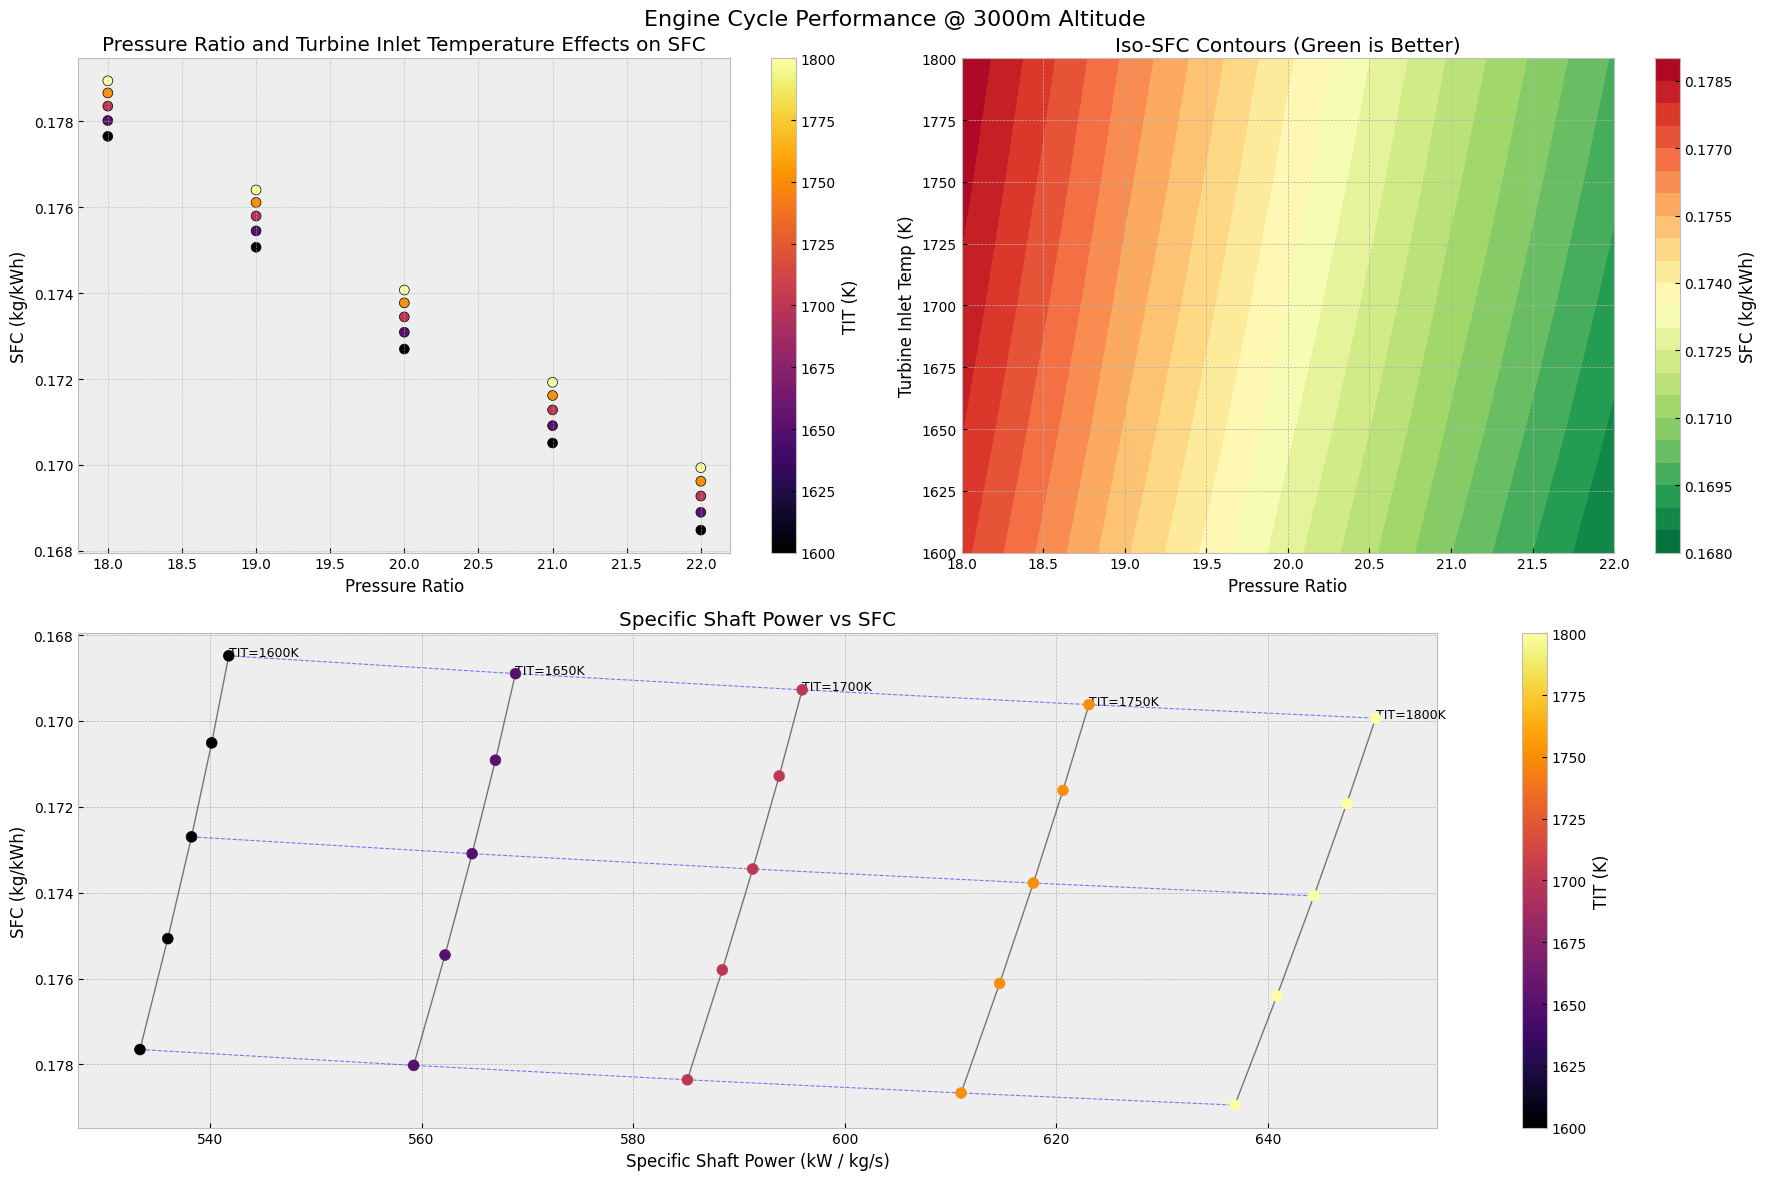

,Cruise_Altitude,TIT (K),PR,Availabe Specific Propeller Power (kJ / kg),Heat In (kJ / kg),SFC (kg / kWh),Inlet Air Density (kg/m^3),Required Air Massflow (kg/s)
1429,3000,1600,22,541.770943,1092.804887,0.168481,0.908942,12.590516
1434,3000,1650,22,568.874465,1150.304887,0.168897,0.908942,11.990652
1439,3000,1700,22,595.977987,1207.804887,0.169275,0.908942,11.445348
1444,3000,1750,22,623.081509,1265.304887,0.169619,0.908942,10.947485
1449,3000,1800,22,650.185031,1322.804887,0.169935,0.908942,10.491130
1428,3000,1600,21,540.156758,1102.670472,0.170511,0.908942,12.628141
1433,3000,1650,21,566.980824,1160.170472,0.170914,0.908942,12.030699
1438,3000,1700,21,593.804890,1217.670472,0.171282,0.908942,11.487234
1443,3000,1750,21,620.628956,1275.170472,0.171617,0.908942,10.990747
1448,3000,1800,21,647.453021,1332.670472,0.171925,0.908942,10.535398


In [4]:
alt_list = np.arange(150, 3100, 50)
temp_list = np.arange(1600, 1850, 50)
pressure_ratio_list = np.arange(18, 23, 1)

df = brayton_cycle_analysis(alt_list, temp_list, pressure_ratio_list)
performance_plot(df, alt_list[-2])

df["Required Air Massflow (kg/s)"] = P / (1000 * df['Availabe Specific Propeller Power (kJ / kg)'])
mask = (df["Required Air Massflow (kg/s)"] >= 11.5) & (df["Required Air Massflow (kg/s)"] <= 13.0)
df[(df['Cruise_Altitude'] == 3000)].sort_values(by="SFC (kg / kWh)")

In [5]:
Alt_H = np.array([0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 
         1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900,
         2000, 2100, 2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900,
         3000, 3100, 3200, 3300, 3400, 3500, 3600, 3700, 3800, 3900,
         4000, 4100, 4200, 4300, 4400, 4500, 4600, 4700, 4800, 4900,
         5000, 5100, 5200, 5300, 5400, 5500, 5600, 5700, 5800, 5900,
         6000, 6100, 6200, 6300, 6400, 6500, 6600, 6700, 6800, 6900,
         7000, 7100, 7200, 7300, 7400, 7500, 7600, 7700, 7800, 7900,
         8000, 8100, 8200, 8300, 8400, 8500, 8600, 8700, 8800, 8900,
         9000, 9100, 9200, 9300, 9400, 9500, 9600, 9700, 9800, 9900,
         10000])

Alt_temp = np.array([288.150,287.952, 287.754, 287.556, 287.358,287.160,286.961, 286.763, 286.565, 286.367,
            286.169,285.971, 285.773, 285.575, 285.377,285.178,284.980, 284.782, 284.584, 284.386,
            284.188,283.990, 283.792, 283.595, 283.397,283.197,282.999, 282.801, 282.603, 282.405,
            282.207,282.008, 281.810, 281.612, 281.414,281.216,281.018, 280.820, 280.622, 280.424,
            280.225,280.027, 279.829, 279.631, 279.433,279.235,279.037, 278.839, 278.640, 278.442,
            278.244,278.046, 277.848, 277.650, 277.452,277.254,277.055, 276.857, 276.659, 276.461,
            276.263,276.065, 275.867, 275.669, 275.471,275.272,275.074, 274.876, 274.678, 274.480,
            274.282,274.084, 273.886, 273.687, 273.489,273.291,273.093, 272.895, 272.697, 272.499,
            272.301,272.102, 271.904, 271.706, 271.508,271.310,271.112, 270.914, 270.716, 270.518,
            270.319,270.121, 269.923, 269.725, 269.527,269.329,269.131, 268.933, 268.734, 268.536,
            268.338])


Alt_rho = np.array([1.2250,1.2214, 1.2178, 1.2143, 1.2107, 1.2072, 1.2036, 1.2001, 1.1966, 1.1931,
          1.1896, 1.1861, 1.1826, 1.1791, 1.1756, 1.1721, 1.1687, 1.1652, 1.1618, 1.1583,
          1.1549, 1.1515, 1.1481, 1.1447, 1.1413, 1.1379, 1.1345, 1.1311, 1.1277, 1.1244,
          1.1210, 1.1177, 1.1144, 1.1110, 1.1077, 1.1044, 1.1011, 1.0978, 1.0945, 1.0912,
          1.0879, 1.0847, 1.0814, 1.0781, 1.0749, 1.0717, 1.0684, 1.0652, 1.0620, 1.0588,
          1.0556, 1.0524, 1.0492, 1.0460, 1.0429, 1.0397, 1.0365, 1.0334, 1.0302, 1.0271,
          1.0240, 1.0209, 1.0178, 1.0146, 1.0115, 1.0085, 1.0054, 1.0023, 0.99923, 0.99617,
           0.99304, 0.98999, 0.98695, 0.98391, 0.98089, 0.97787, 0.97485, 0.97185, 0.96885, 
           0.96586, 0.96287, 0.95989, 0.95692, 0.95396, 0.95100, 0.94805, 0.94511, 0.94217, 
           0.93924, 0.93632, 0.93341, 0.93050, 0.92760, 0.92470, 0.92182, 0.91894, 0.91606, 
           0.91320, 0.91034, 0.90748, 0.90464])

5.3413940334257255 0.49188558552107897 0.09208936514380424 0.3915477227370946


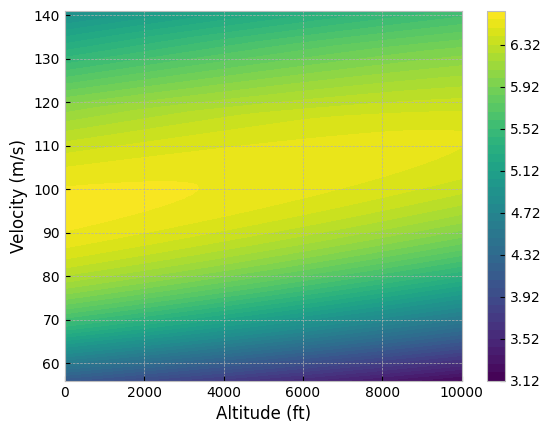

6.595041005525542
39.0
56.0


In [6]:
## L/D calculations ##

def get_LD(altitude,velocity,weight):
    
    Temp = np.interp(altitude, Alt_H, Alt_temp)
    sp_sound = np.sqrt(1.4*287*Temp)
    M = velocity/sp_sound

    Mach_nos = np.array([0.2,0.35,0.4,0.5,0.6])
    C_d0s = np.array([0.0684,0.0686112,0.069598,0.0746,0.088328])
    ks = np.array([0.08,0.087,0.095,0.115,0.22])

    C_d0_out = np.interp(M, Mach_nos, C_d0s)
    #print(C_d0_out)
    k_out = np.interp(M, Mach_nos, ks)
    #print(k_out)

    gravity = 9.81 #m/s^2
    wing_area = 35.49 # m^2
    density = np.interp(altitude, Alt_H, Alt_rho)
    C_L = (weight*gravity) / (0.5 * density * wing_area * (velocity**2))

    LD = C_L / (C_d0_out + k_out*(C_L**2))

    C_D = C_d0_out + k_out*(C_L**2)

    return LD, C_L, C_D, M

search_speed = 93 # m/s
cruise_speed = 133 # m/s

LD, C_L, C_D, M = get_LD(500,cruise_speed,19000)
print (LD, C_L, C_D, M)

def LD_max():
    altitude = np.linspace(0,10000,10001)
    velocity = np.linspace(56,141,86)
    alt, vel = np.meshgrid(altitude,velocity)
    LD, C_L, C_D, M = get_LD(alt,vel,19000)
    idx = np.unravel_index(np.argmax(LD), LD.shape)
    alt_opt = altitude[idx[0]]
    vel_opt = velocity[idx[1]]
    fig,ax = plt.subplots()
    plt.contourf(altitude,velocity,LD,levels=50)
    plt.ylabel("Velocity (m/s)")
    plt.xlabel("Altitude (ft)")
    plt.colorbar()
    plt.show()
    print(np.max(LD))
    print(alt_opt)
    print(vel_opt)

LD_max()

In [27]:
def prop_design_hover(T_max, D, blades=3, alpha_deg=5.0, Cl = 1.1):
    R = D / 2
    A = np.pi * R ** 2
    a = 340 # speed of sound
    v_tip = 0.7 * a
    rho = 1.2

    n_rps = v_tip / (np.pi * D)
    n_rpm = n_rps * 60
    
    # calculating downwash velocity to calculate blade angle addition factor, phi
    # based on momentum equation, T = 0.5 rho A v^2
    v_i = np.sqrt(T_max / (2 * rho * A))
    r_stations = np.linspace(0.1 * R, R, 20)
    v_t = 2 * np.pi * n_rps * r_stations
    phi = np.arctan(v_i / v_t)
    
    # alpha = AoA of root, beta = AoA of tip
    alpha_rad = np.radians(alpha_deg)
    beta_rad = phi + alpha_rad
    beta_deg = np.degrees(beta_rad)

    # W is relative velocity in each stations
    # blade calculation using Blade Element Momentum Theory
    W = np.sqrt(v_i ** 2 + v_t **2)
    psi = np.arctan(v_i / v_t)
    chord_ideal = (8 * np.pi * r_stations * v_i **2) / (blades * W**2 * Cl * np.cos(psi))

    # taking the 75% radius as a reference station, as significant portion of the thrust
    # is from the outer 25% of the blade, and finally linearising the taper
    idx_75 = np.argmin(np.abs(r_stations - 0.75*R))
    chord_75 = chord_ideal[idx_75]
    chord_tip = chord_ideal[-1]
    slope = (chord_tip - chord_75) / (r_stations[-1] - r_stations[idx_75])

    chord_real = slope * (r_stations - r_stations[-1]) + chord_tip
    chord_real = np.minimum(chord_real, 0.85)
    # print(v_t, '\n', chord_real)

    # taking the integral to calculate the force through the blade
    dT_ideal = blades * 0.5 * rho * W**2 * chord_ideal * Cl * np.cos(phi)
    dT_real = blades * 0.5 * rho * W**2 * chord_real * Cl * np.cos(phi)

    T_ideal = simpson(dT_ideal, x=r_stations) # taking the integrals
    T_real = simpson(dT_real, x=r_stations)
    T_loss = T_ideal - T_real
    T_loss_pct = (T_loss / T_ideal) * 100

    print("\n--- Main Propeller Design ---")
    print(f"Prop Diameter: {D:.2f} m")
    print(f"Single Engine Failure RPM: {n_rpm:.0f} RPM")
    print(f"Induced Wash (v_i): {v_i:.2f} m/s")
    print(f"Max Tip Speed:  {v_tip:.1f} m/s (Mach 0.7)")
    print(f"Root Chord, Ideal:     {chord_ideal[0]:.3f} m")
    print(f"Root Chord, Real:     {chord_real[0]:.3f} m")
    print(f"Tip Chord, Ideal:      {chord_ideal[-1]:.3f} m")
    print(f"Tip Chord, Real:      {chord_real[-1]:.3f} m")

    print("\n--- Forward Integration Results ---")
    print(f"Target Thrust:      {T_max/1000:.1f} kN")
    print(f"Ideal Blade Thrust: {T_ideal/1000:.1f} kN")
    print(f"Practical Thrust:   {T_real/1000:.1f} kN")
    print(f"Thrust Penalty:     {T_loss/1000:.1f} kN ({T_loss_pct:.2f}%)")

    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

    ax1.plot(r_stations, chord_ideal, 'r--', linewidth=2, label='BEMT Chord')
    ax1.plot(r_stations, chord_real, 'b-', linewidth=2, label='Truncated Chord')
    ax1.set_ylabel('Chord Length (m)', color='black')
    ax1.set_xlabel('Radius (m)')
    ax1.tick_params(axis='y', labelcolor='black')
    ax1.grid(True, linestyle='--', alpha=0.7)
    ax1.legend(loc='best')

    # ax1_twin = ax1.twinx()
    # ax1_twin.plot(r_stations, beta_deg, 'g-o', linewidth=2, label='Twist Angle')
    # ax1_twin.set_ylabel('Twist Angle, Beta (°)', color='green')
    # ax1_twin.tick_params(axis='y', labelcolor='green')

    ax1.set_title(f'Spanwise Chord Distribution')
    # lines_1, labels_1 = ax1.get_legend_handles_labels()
    # lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
    # ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='best')

    ax2.plot(r_stations, dT_ideal / 1000, 'r--', label='BEMT')
    ax2.plot(r_stations, dT_real / 1000, 'b-', linewidth=2, label='Truncated Chord')
    ax2.fill_between(r_stations, dT_ideal / 1000, dT_real / 1000, color='red', alpha=0.2, label='Lost Thrust vs Ideal')
    ax2.set_xlabel('Radius (m)')
    ax2.set_ylabel('Section Thrust (kN/m)')
    ax2.set_title('Spanwise Thrust Distribution')
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.legend(loc='best')

    plt.tight_layout()
    plt.show()

    return {"Stations Radius:" : r_stations,
            "Station Twist Angle:" : beta_deg,
            "Station Chord Length:" :chord_real}

def prop_design_mission(D, altitude, condition, v_inf, blades=3, alpha_deg=5.0, hover_results=None):
    R = D/2
    P, T, rho = ISA_atmosphere(altitude)
    a = np.sqrt(1.4 * 287.0 * T)
    v_tip = 0.7 * a

    if v_inf >= v_tip:
        raise ValueError("Forward Speed > Max Tip Mach Number")
    
    n_rps = np.sqrt(v_tip ** 2 - v_inf ** 2) / (np.pi * D)
    n_rpm = n_rps * 60
    r_stations = np.linspace(0.1 * R, R, 20)
    v_t = 2 * np.pi * n_rps * r_stations
    phi = np.arctan(v_inf / v_t)

    alpha = np.radians(alpha_deg)
    beta_rad = phi + alpha
    beta_deg = np.degrees(beta_rad)

    print(f"\n--- {condition} Propeller Design ({altitude} m) ---")
    print(f"Target V_inf:      {v_inf:.1f} m/s (Mach {v_inf/a:.3f})")
    print(f"{condition} RPM:   {n_rpm:.0f} RPM (Reduced from Hover to keep Mach 0.7)")
    print(f"Total Tip Speed:   {v_t[-1]:.1f} m/s (Mach {v_t[-1]/a})")
    print(f"Air Density:       {rho:.3f} kg/m^3")

    if hover_results is not None:
        beta_hover = hover_results['Station Twist Angle:']
        idx_75 = np.argmin(np.abs(r_stations - 0.75 * R))
        shift_ang = (beta_hover[idx_75] - beta_deg[idx_75]).item()

        print("\n--- Variable Pitch Mechanism ---")
        print(f"75% Station Cruise Angle: {beta_deg[idx_75]:.1f} deg")
        print(f"75% Station Hover Angle:  {beta_hover[idx_75]:.1f} deg")
        print(f"Required Pitch Shift: {shift_ang:.1f} degrees ({condition} -> Hover)")

    else:
        pass
    
    return {"Twist Angle (Deg):" : beta_deg,
            "Stations Radius:": r_stations,
            "N_RPM:": n_rpm,
            "Station Chord:" : hover_results['Station Chord Length:'],
            "Hover Shift:" : shift_ang}

def evaluate_manufactured_hover(T_max, D, hover_results, cruise_results, shift_ang, blades=3):
    r_stations = hover_results["Stations Radius:"]
    chord_real = hover_results["Station Chord Length:"]
    beta_cruise = cruise_results["Twist Angle (Deg):"]
    
    # Hover Kinematics
    rho = 1.2
    R = D / 2
    A = np.pi * R ** 2
    a = 340 
    v_tip = 0.7 * a
    n_rps = v_tip / (np.pi * D)
    
    v_i = np.sqrt(T_max / (2 * rho * A))
    v_t = 2 * np.pi * n_rps * r_stations
    phi = np.arctan(v_i / v_t)
    W = np.sqrt(v_i ** 2 + v_t **2)
    
    psi = np.arctan(v_i / v_t)
    chord_ideal = (8 * np.pi * r_stations * v_i **2) / (blades * W**2 * 1.1 * np.cos(psi))
    beta_mfg = beta_cruise + shift_ang
    alpha_rad_mfg = np.radians(beta_mfg) - phi
    alpha_deg_mfg = np.degrees(alpha_rad_mfg)

    # clipping Cl values
    Cl_mfg = 0.11 * (alpha_deg_mfg + 5.0)
    Cl_mfg = np.clip(Cl_mfg, -0.2, 1.4) 

    # taking the spanwise integral for thrust
    dT_ideal = blades * 0.5 * rho * W**2 * chord_ideal * 1.1 * np.cos(phi)
    dT_trunc = blades * 0.5 * rho * W**2 * chord_real * 1.1 * np.cos(phi)
    dT_mfg = blades * 0.5 * rho * W**2 * chord_real * Cl_mfg * np.cos(phi)
    T_ideal = simpson(dT_ideal, x=r_stations)
    T_trunc = simpson(dT_trunc, x=r_stations)
    T_mfg = simpson(dT_mfg, x=r_stations)

    loss_trunc_pct = ((T_ideal - T_trunc) / T_ideal) * 100
    loss_mfg_pct = ((T_ideal - T_mfg) / T_ideal) * 100
    additional_twist_penalty = loss_mfg_pct - loss_trunc_pct

    print("\n--- Final OEI Hover Aerodynamic Evaluation ---")
    print(f"Target Thrust:                 {T_max/1000:.1f} kN")
    print(f"1. Ideal BEMT Thrust:     {T_ideal/1000:.1f} kN")
    print(f"2. Target Twist Angle:  {T_trunc/1000:.1f} kN (-{loss_trunc_pct:.1f}% loss)")
    print(f"3. Cruise Twist Angle + Pitch:   {T_mfg/1000:.1f} kN (-{loss_mfg_pct:.1f}% total loss)")
    print(f"-> Penalty solely from twist mismatch: {additional_twist_penalty:.1f}%")

    plt.figure(figsize=(8, 4))
    plt.plot(r_stations, dT_ideal / 1000, 'r--', linewidth=2, label='BEMT')
    plt.plot(r_stations, dT_trunc / 1000, 'b-.', linewidth=2, label='BEMT with Truncated Chord')
    plt.plot(r_stations, dT_mfg / 1000, 'g-o', linewidth=2, label=f'BEMT Cruise-Optimised, {shift_ang}° Pitch')
    plt.fill_between(r_stations, dT_trunc / 1000, dT_mfg / 1000, color='green', alpha=0.2, label='Pitched Cruise-Optimised Blade Recovered Thrust')
    
    plt.xlabel('Radius (m)')
    plt.ylabel('Section Thrust (kN/m)')
    plt.title('Spanwise Hover Thrust Distribution, Pitched Cruise-Optimised Blade')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
def CFD_data(data):
    df = pd.read_csv(data)
    df['r'] = np.sqrt(df['X (m)']**2 + df['Y (m)']**2)
    df['Thrust_N'] = -df['Pressure (Pa)'] * df['Area[k] (m^2)']

    n_bins = 40
    r_min, r_max = df['r'].min(), df['r'].max()
    bins = np.linspace(r_min, r_max, n_bins + 1)
    dr = (r_max - r_min) / n_bins
    r_centre = (bins[:-1] + bins[1:]) / 2

    dT_dr = []
    for i in range(n_bins):
        mask = (df['r'] >= bins[i]) & (df['r'] < bins[i+1])
        thrust_bin = df.loc[mask, 'Thrust_N'].sum()
        dT_dr.append(thrust_bin / dr)

    return {'r': r_centre,  'Thrust_N': np.array(dT_dr)}

def evaluate_bemt_cfd(bemt_result, cfd_result, 
                      v_inf, rho, blades=3, pitch_offset=0.0):
    
    r_stations = np.array(bemt_result['Stations Radius:'])
    chord = np.array(bemt_result['Station Chord:'])
    beta_deg = np.array(bemt_result['Twist Angle (Deg):']) + pitch_offset
    omega = bemt_result['N_RPM:'] * (2 * np.pi / 60)
    v_t = omega * r_stations

    W = np.sqrt(v_inf**2 + v_t**2)
    phi_rad = np.arctan(v_inf / v_t)
    alpha_deg = beta_deg - np.degrees(phi_rad)
    
    Cl = 0.11 * (alpha_deg + 5.0)
    Cl = np.clip(Cl, -0.2, 1.4)

    dT_bemt = blades * 0.5 * rho * W**2 * chord * Cl * np.cos(phi_rad) / 6
    T_bemt = simpson(dT_bemt, x=r_stations)

    r_cfd = cfd_result['r']
    dT_cfd = cfd_result['Thrust_N']
    T_cfd = simpson(dT_cfd, x=r_cfd)
    error_pct = abs(T_bemt - T_cfd) / T_bemt * 100


    if v_inf > 100:
        case_name = 'Cruise (133 m/s)'
    else:
        case_name = 'Search'

    print(f"\n--- {case_name} Aerodynamic Validation ---")
    print(f"BEMT Analytical Thrust: {T_bemt/1000:.2f} kN")
    print(f"CFD Integrated Thrust:  {T_cfd/1000:.2f} kN")
    print(f"Delta:                  {error_pct:.2f}%")

    fig, ax = plt.subplots(figsize=(8,4))
    ax.plot(r_stations, dT_bemt, c='r', linewidth=2, label=f'1D BEMT, Analytical, {T_bemt/1000:.2f}kN')
    ax.plot(r_cfd, dT_cfd, c='b', linewidth=2, label=f'3D CFD RANS, {T_cfd/1000:.2f}kN')
    ax.plot([], [], ' ', label=f'Error: {error_pct:.2f}%')
    ax.set_xlabel('Radius (m)')
    ax.set_ylabel('Section Thrust, dT/dr (N/m)')
    ax.set_title(f'Spanwise Thrust Distribution: BEMT vs CFD ({case_name})')
    ax.legend()
    ax.grid(True, linestyle='--')
    plt.show()



--- Main Propeller Design ---
Prop Diameter: 11.48 m
Single Engine Failure RPM: 396 RPM
Induced Wash (v_i): 27.39 m/s
Max Tip Speed:  238.0 m/s (Mach 0.7)
Root Chord, Ideal:     3.798 m
Root Chord, Real:     0.850 m
Tip Chord, Ideal:      0.575 m
Tip Chord, Real:      0.575 m

--- Forward Integration Results ---
Target Thrust:      186.4 kN
Ideal Blade Thrust: 184.5 kN
Practical Thrust:   159.7 kN
Thrust Penalty:     24.8 kN (13.44%)


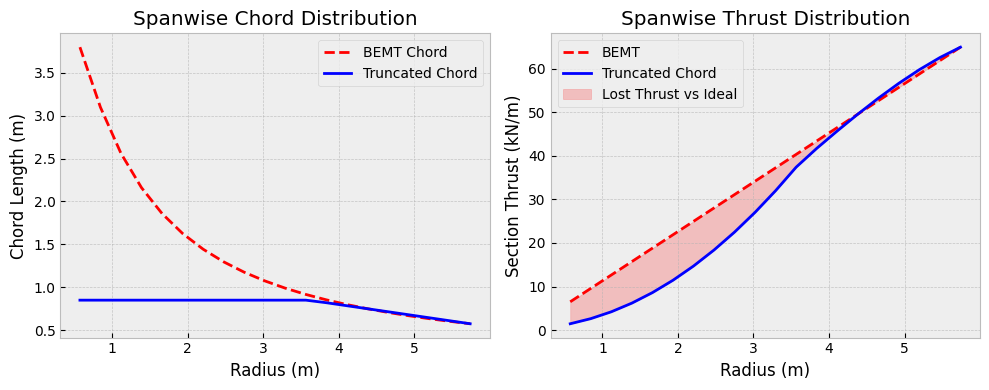


--- Cruise Propeller Design (3000 m) ---
Target V_inf:      133.0 m/s (Mach 0.405)
Cruise RPM:   312 RPM (Reduced from Hover to keep Mach 0.7)
Total Tip Speed:   187.6 m/s (Mach 0.5710755987589125)
Air Density:       0.909 kg/m^3

--- Variable Pitch Mechanism ---
75% Station Cruise Angle: 47.9 deg
75% Station Hover Angle:  13.6 deg
Required Pitch Shift: -34.3 degrees (Cruise -> Hover)

--- Search Propeller Design (150 m) ---
Target V_inf:      93.0 m/s (Mach 0.274)
Search RPM:   364 RPM (Reduced from Hover to keep Mach 0.7)
Total Tip Speed:   218.8 m/s (Mach 0.6442386932520948)
Air Density:       1.207 kg/m^3

--- Variable Pitch Mechanism ---
75% Station Cruise Angle: 34.1 deg
75% Station Hover Angle:  13.6 deg
Required Pitch Shift: -20.5 degrees (Search -> Hover)

--- Final OEI Hover Aerodynamic Evaluation ---
Target Thrust:                 186.4 kN
1. Ideal BEMT Thrust:     184.5 kN
2. Target Twist Angle:  159.7 kN (-13.4% loss)
3. Cruise Twist Angle + Pitch:   181.7 kN (-1.5% total

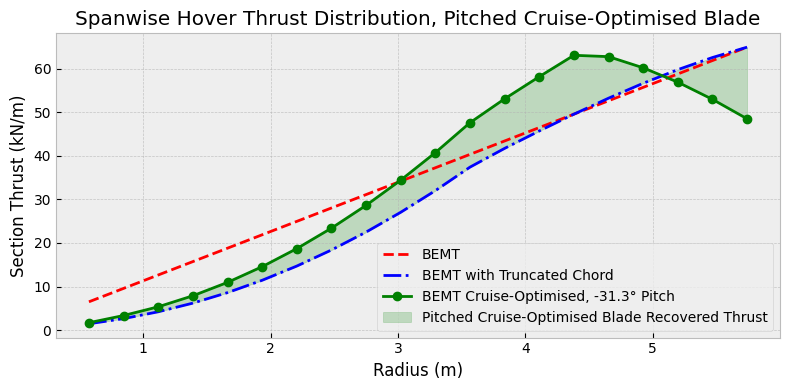


--- Cruise (133 m/s) Aerodynamic Validation ---
BEMT Analytical Thrust: 5.56 kN
CFD Integrated Thrust:  5.44 kN
Delta:                  2.28%


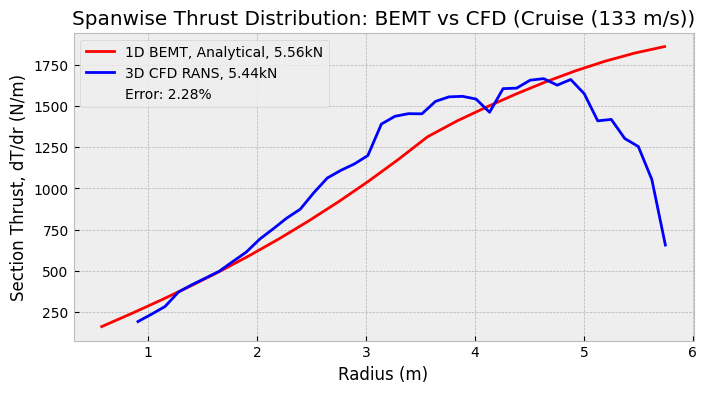


--- Search Aerodynamic Validation ---
BEMT Analytical Thrust: 4.49 kN
CFD Integrated Thrust:  4.81 kN
Delta:                  7.05%


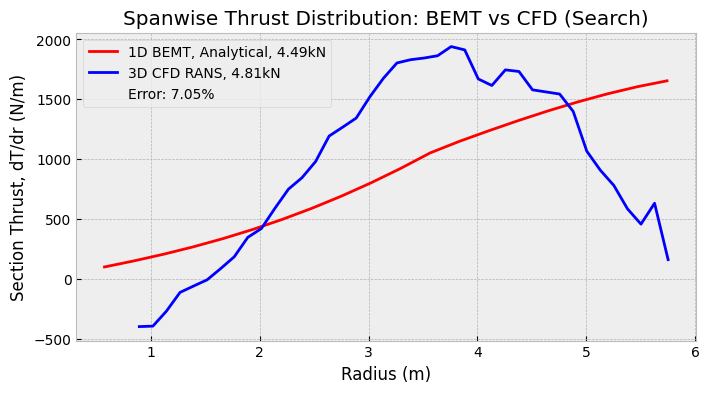

In [28]:
hover = prop_design_hover(thrust_maximum, prop_diameter)
cruise = prop_design_mission(prop_diameter, 3000, "Cruise", v_inf=cruise_speed, hover_results=hover)
search = prop_design_mission(prop_diameter, 150, "Search", v_inf=search_speed, hover_results=hover)

# hover, cruise['Twist Angle (Deg):'], search['Twist Angle (Deg):'], cruise['N_RPM:'], search['N_RPM:'] #, evaluate_manufactured_hover(thrust_maximum, prop_diameter, hover, cruise['Twist Angle (Deg)'], cruise_shift)
cruise_cfd = CFD_data('pressure_normal_xyz_coord_cruise.csv')
search_cfd = CFD_data('pressure_normal_xyz_coord_search.csv')
evaluate_manufactured_hover(thrust_maximum, prop_diameter, hover, cruise, -31.3)
evaluate_bemt_cfd(cruise, cruise_cfd, 133, 0.909, 0.9)
evaluate_bemt_cfd(search, search_cfd, 93, 1.205, 0.5)

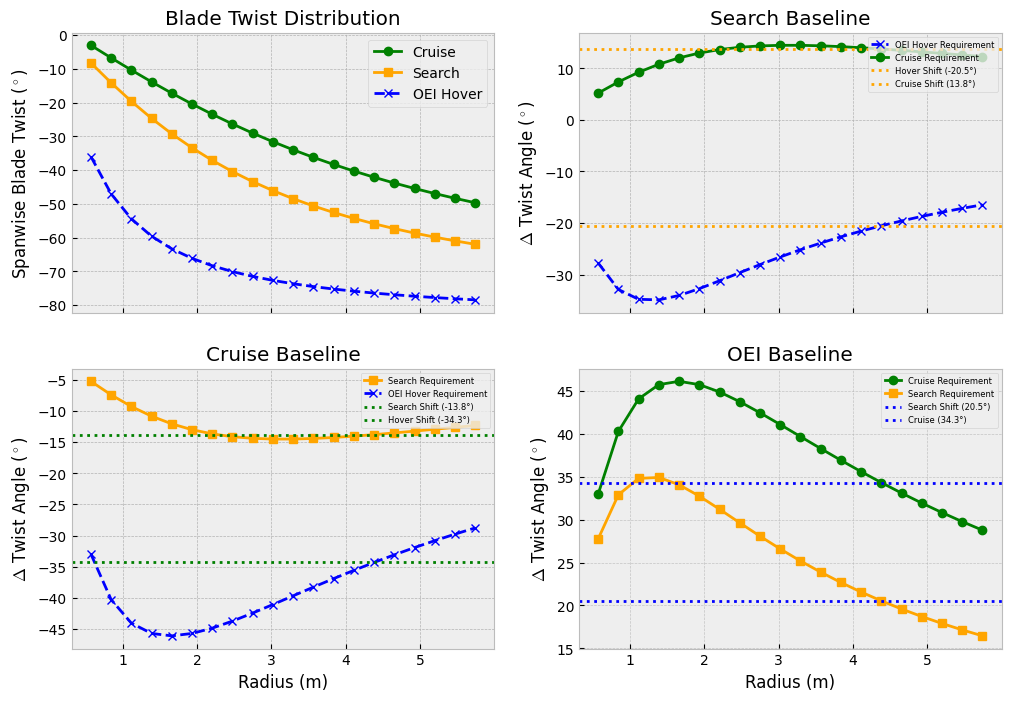

In [10]:
r_stations = hover["Stations Radius:"]
idx_75 = np.argmin(np.abs(r_stations - 0.75 * prop_diameter / 2))

beta_hover = hover["Station Twist Angle:"]
beta_cruise = cruise["Twist Angle (Deg):"]
beta_search = search["Twist Angle (Deg):"]

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), sharex=True)
# Baseline Requirements
ax[0,0].plot(r_stations, beta_cruise - 90, 'g-o', linewidth=2, label='Cruise')
ax[0,0].plot(r_stations, beta_search - 90, 'orange', marker='s', linewidth=2, label='Search')
ax[0,0].plot(r_stations, beta_hover - 90, 'b--x', linewidth=2, label='OEI Hover')

ax[0,0].set_ylabel(r'Spanwise Blade Twist ($^\circ$)')
ax[0,0].set_title('Blade Twist Distribution')
ax[0,0].legend()

# Cruise Baselining
delta_hc = beta_hover - beta_cruise
delta_sc = beta_search - beta_cruise
search_shift = delta_sc[idx_75]
hover_shift = delta_hc[idx_75]

# ax2.plot(r_stations, beta_cruise - beta_cruise, 'g-o', linewidth=2, label='Cruise, Zero Variable Pitch')
ax[1,0].plot(r_stations, delta_sc, 'orange', marker='s', linewidth=2, label='Search Requirement')
ax[1,0].plot(r_stations, delta_hc, 'b--x', linewidth=2, label='OEI Hover Requirement')
ax[1,0].axhline(y=search_shift, color='green', linestyle=':', linewidth=2, label=f'Search Shift ({search_shift:.1f}°)')
ax[1,0].axhline(y=hover_shift, color='green', linestyle=':', linewidth=2, label=f'Hover Shift ({hover_shift:.1f}°)')
ax[1,0].set_xlabel('Radius (m)')
ax[1,0].set_ylabel(r'$\Delta$ Twist Angle ($^\circ$)')
ax[1,0].set_title('Cruise Baseline')
ax[1,0].legend(loc='upper right',prop={'size': 6})

# Search Baselining
delta_hs = beta_hover - beta_search
delta_cs = beta_cruise - beta_search
cruise_shift = delta_cs[idx_75]
hover_shift = delta_hs[idx_75]

# ax3.plot(r_stations, beta_search - beta_search, 'orange', marker='s', linewidth=2, label='Search, Zero Variable Pitch')
ax[0,1].plot(r_stations, delta_hs, 'b--x', linewidth=2, label='OEI Hover Requirement')
ax[0,1].plot(r_stations, delta_cs, 'g-o', linewidth=2, label='Cruise Requirement')
ax[0,1].axhline(y=hover_shift, color='orange', linestyle=':', linewidth=2, label=f'Hover Shift ({hover_shift:.1f}°)')
ax[0,1].axhline(y=cruise_shift, color='orange', linestyle=':', linewidth=2, label=f'Cruise Shift ({cruise_shift:.1f}°)')
ax[0,1].set_ylabel(r'$\Delta$ Twist Angle ($^\circ$)')
ax[0,1].set_title('Search Baseline')
ax[0,1].legend(loc='upper right',prop={'size': 6})

# Hover Baselining
delta_ch = beta_cruise - beta_hover
delta_sh = beta_search - beta_hover
cruise_shift = delta_ch[idx_75]
search_shift = delta_sh[idx_75]

# ax4.plot(r_stations, beta_hover - beta_hover, 'b--x', linewidth=2, label='OEI, Zero Variable Pitch')
ax[1,1].plot(r_stations, delta_ch, 'g-o', linewidth=2, label='Cruise Requirement')
ax[1,1].plot(r_stations, delta_sh, 'orange', marker='s', linewidth=2, label='Search Requirement')
ax[1,1].axhline(y=search_shift, color='blue', linestyle=':', linewidth=2, label=f'Search Shift ({search_shift:.1f}°)')
ax[1,1].axhline(y=cruise_shift, color='blue', linestyle=':', linewidth=2, label=f'Cruise ({cruise_shift:.1f}°)')
ax[1,1].set_xlabel('Radius (m)')
ax[1,1].set_ylabel(r'$\Delta$ Twist Angle ($^\circ$)')
ax[1,1].set_title('OEI Baseline')
ax[1,1].legend(loc='upper right',prop={'size': 6})

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


In [11]:
# naca_4412_norm = """1.0000     0.0013
# 0.9500     0.0147
# 0.9000     0.0271
# 0.8000     0.0489
# 0.7000     0.0669
# 0.6000     0.0814
# 0.5000     0.0919
# 0.4000     0.0980
# 0.3000     0.0976
# 0.2500     0.0941
# 0.2000     0.0880
# 0.1500     0.0789
# 0.1000     0.0659
# 0.0750     0.0576
# 0.0500     0.0473
# 0.0250     0.0339
# 0.0125     0.0244
# 0.0000     0.0000
# 0.0125     -0.0143
# 0.0250     -0.0195
# 0.0500     -0.0249
# 0.0750     -0.0274
# 0.1000     -0.0286
# 0.1500     -0.0288
# 0.2000     -0.0274
# 0.2500     -0.0250
# 0.3000     -0.0226
# 0.4000     -0.0180
# 0.5000     -0.0140
# 0.6000     -0.0100
# 0.7000     -0.0065
# 0.8000     -0.0039
# 0.9000     -0.0022
# 0.9500     -0.0016
# 1.0000     -0.0013"""

# coords = np.array([list(map(float, line.split())) for line in naca_4412_norm.strip().split('\n')])
# x_norm = coords[:, 0]
# y_norm = coords[:, 1]

# r_stations = hover['Stations Radius:']
# beta_deg = cruise_twist["Twist Angle (Deg):"]
# chord_length = hover['Station Chord Length:']

# # beta_hover = hover["Station Twist Angle:"]
# # beta_cruise = cruise_twist["Twist Angle (Deg):"]
# # beta_search = search_twist["Twist Angle (Deg):"]

# output_dir = 'airfoil_coord_cruise'
# os.makedirs(output_dir, exist_ok=True)

# for i in range(len(r_stations)):
#     r = r_stations[i]
#     c = chord_length[i]
#     beta = np.radians(beta_deg[i])

#     x_scaled = (x_norm * c) - (0.25 * c)
#     y_scaled = (y_norm * c)

#     x_3d = x_scaled * np.cos(-beta) - y_scaled * np.sin(-beta)
#     y_3d = x_scaled * np.sin(-beta) + y_scaled * np.cos(-beta)
#     z_3d = np.full_like(x_3d, r)

#     filename = f"{output_dir}/station_{i+1:02d}_r{r:.2f}.csv"

#     with open(filename, 'w') as f:
#         for j in range(len(x_3d)):
#             f.write(f"{x_3d[j]:.6f},{y_3d[j]:.6f},{z_3d[j]:.6f}\n")

#     print(f'Generated {filename}')


In [12]:
"""
AET Task 3 — Section 5: Mean Blade Angles and Number of Blades
V-22 Osprey Search-and-Rescue Turboshaft Engine

Assumptions:
  - Compressor: axial entry (alpha1=0) to each rotor; stator returns to axial
  - Turbines:   axial exit  (alpha2=0) from each rotor; NGV provides all swirl
  - Constant axial velocity Vx through each component
  - Constant mean radius through compressor (r_mean fixed)
  - Constant mean radius through LPT (r_mean fixed at 199.7 mm)
  - HPT mean radius constant at 164.63 mm
"""

import numpy as np

# fluid properties
cp_cold = 1005.0   # J/(kg·K)  compressor
cp_hot  = 1150.0   # J/(kg·K)  turbines

# --- COMPRESSOR GEOMETRY (Based on Optimal Inlet Summary) ---
RPM_HPC     = 28722
r_tip_HPC   = 0.1615   # m
r_hub_HPC   = 0.0565   # m
r_mean_HPC  = (r_tip_HPC + r_hub_HPC) / 2  # 0.1090 m (constant)
omega_HPC   = RPM_HPC * 2 * np.pi / 60
U_HPC       = 327.89   # m/s
Vx_HPC      = 163.94   # m/s

# 13-Stage HPC Data: (ΔT_K, blade_height_mm)
HPC_stages_data = [
    (24.46, 86.78), (26.53, 71.79), (28.78, 59.43), (31.23, 49.23), 
    (33.88, 40.81), (36.75, 33.84), (39.62, 28.11), (39.62, 23.69), 
    (39.62, 20.21), (39.62, 17.42), (39.62, 15.16), (39.62, 13.30), 
    (23.00, 12.37)
]

# --- HPT GEOMETRY ---
RPM_HPT     = 28722.0
r_mean_HPT  = 0.16463  # m
omega_HPT   = RPM_HPT * 2 * np.pi / 60
U_HPT       = omega_HPT * r_mean_HPT
Vx_HPT      = 321.85   # m/s
HPT_stages_data = [(221.4, 14.0), (176.4, 23.0)]

# --- LPT GEOMETRY ---
RPM_LPT     = 14000.0
r_mean_LPT  = 0.1997   # m
omega_LPT   = RPM_LPT * 2 * np.pi / 60
U_LPT       = omega_LPT * r_mean_LPT
Vx_LPT      = 322.08   # m/s
LPT_stages_data = [(128.0, 35.58), (128.0, 55.46), (128.0, 91.63)]

# design parameters
Z_zweifel   = 0.8   
sc_HPC      = 0.8   
AR_HPC      = 1.5   
AR_HPT      = 1.2   
AR_LPT      = 1.5   
DH_LIMIT    = 0.72  
PSI_LIMIT   = 2.0   

def blade_count(r_mean, h_m, sc, AR):
    c = h_m / AR
    s = sc * c
    N = int(np.round(2 * np.pi * r_mean / s))
    return c, s, N

def analyse_compressor_stage(U, Vx, dT, h_mm, r_mean):
    h = h_mm / 1000.0
    beta1 = np.arctan(U / Vx)
    tan_a2 = cp_cold * dT / (U * Vx)
    alpha2 = np.arctan(tan_a2)
    tan_b2 = (U / Vx) - tan_a2
    beta2  = np.arctan(tan_b2)
    W1 = Vx / np.cos(beta1)
    W2 = Vx / np.cos(beta2)
    DH = W2 / W1
    psi = cp_cold * dT / U**2
    c_r, s_r, N_rotor  = blade_count(r_mean, h, sc_HPC, AR_HPC)
    c_s, s_s, N_stator = blade_count(r_mean, h, sc_HPC, AR_HPC)
    return {
        "alpha2_deg": np.degrees(alpha2), "beta1_deg": np.degrees(beta1),
        "beta2_deg": np.degrees(beta2), "DH": DH, "psi": psi,
        "N_rotor": N_rotor, "N_stator": N_stator, "DH_pass": DH >= (DH_LIMIT - 0.001)
    }

def analyse_turbine_stage(U, Vx, dT, h_mm, r_mean, AR):
    h = h_mm / 1000.0
    tan_a1 = cp_hot * dT / (U * Vx)
    alpha1 = np.arctan(tan_a1)
    tan_b1 = tan_a1 - (U / Vx)
    beta1  = np.arctan(tan_b1)
    tan_b2 = -U / Vx
    beta2  = np.arctan(tan_b2)
    psi = cp_hot * dT / U**2
    sc_ngv = Z_zweifel / np.sin(2 * alpha1)
    c_ngv, s_ngv, N_ngv = blade_count(r_mean, h, sc_ngv, AR)
    denom = 2 * np.cos(beta2)**2 * (np.tan(abs(beta1)) + np.tan(abs(beta2)))
    sc_rot = Z_zweifel / denom
    c_rot, s_rot, N_rotor = blade_count(r_mean, h, sc_rot, AR)
    return {
        "alpha1_deg": np.degrees(alpha1), "beta1_deg": np.degrees(beta1),
        "beta2_deg": np.degrees(beta2), "psi": psi, "sc_ngv": sc_ngv,
        "sc_rotor": sc_rot, "N_ngv": N_ngv, "N_rotor": N_rotor, "psi_pass": psi <= PSI_LIMIT
    }

# --- PROCESS RESULTS ---
hpc_res = [analyse_compressor_stage(U_HPC, Vx_HPC, dt, h, r_mean_HPC) for dt, h in HPC_stages_data]
hpt_res = [analyse_turbine_stage(U_HPT, Vx_HPT, dt, h, r_mean_HPT, AR_HPT) for dt, h in HPT_stages_data]
lpt_res = [analyse_turbine_stage(U_LPT, Vx_LPT, dt, h, r_mean_LPT, AR_LPT) for dt, h in LPT_stages_data]

# --- OUTPUT: COMPRESSOR ---
HPC_SELECT = {1: "FRONT", 7: "MIDDLE", 13: "REAR"}
SEP = "─" * 105
print(SEP); print("COMPRESSOR STAGE ANALYSIS (13 STAGES)"); print(SEP)
print(f"  U_mean = {U_HPC:.2f} m/s | Vx = {Vx_HPC:.2f} m/s | RPM = {RPM_HPC}")
print(f"  β₁ is CONSTANT = {hpc_res[0]['beta1_deg']:.1f}° for all stages\n")
hdr = f"{'Stg':>4} {'Pos':>8} {'ΔT K':>6} {'h mm':>6} {'β₁°':>6} {'β₂°':>6} {'α₂°':>6} {'ψ':>6} {'DH':>6} {'N_R':>4} {'N_S':>4} {'Limit':>7}"
print(hdr); print("─" * len(hdr))
for i, r in enumerate(hpc_res):
    pos = HPC_SELECT.get(i+1, "")
    limit = "PASS ✓" if r["DH_pass"] else "FAIL ✗"
    dt, h = HPC_stages_data[i]
    print(f"  {i+1:>2} {pos:>8} {dt:>6.2f} {h:>6.2f} {r['beta1_deg']:>6.1f} {r['beta2_deg']:>6.1f} {r['alpha2_deg']:>6.1f} {r['psi']:>6.3f} {r['DH']:>6.2f} {r['N_rotor']:>4} {r['N_stator']:>4} {limit:>7}")

# --- OUTPUT: HPT ---
HPT_SELECT = {1: "FRONT", 2: "REAR"}
print("\n" + SEP); print("HIGH PRESSURE TURBINE (HPT) STAGE ANALYSIS"); print(SEP)
print(f"  U_HPT = {U_HPT:.2f} m/s | Vx = {Vx_HPT:.2f} m/s | RPM = {int(RPM_HPT)}")
print(f"  β₂ is CONSTANT = {hpt_res[0]['beta2_deg']:.1f}° for all HPT stages\n")
hdr2 = f"{'Stg':>4} {'Pos':>8} {'ΔT K':>6} {'h mm':>6} {'α₁°':>7} {'β₁°':>7} {'β₂°':>7} {'ψ':>6} {'s/c NGV':>8} {'s/c Rot':>8} {'N_NGV':>6} {'N_R':>4} {'Limit':>7}"
print(hdr2); print("─" * len(hdr2))
for i, r in enumerate(hpt_res):
    pos = HPT_SELECT.get(i+1, "")
    limit = "PASS ✓" if r["psi_pass"] else "FAIL ✗"
    dt, h = HPT_stages_data[i]
    print(f"  {i+1:>2} {pos:>8} {dt:>6.1f} {h:>6.1f} {r['alpha1_deg']:>7.1f} {r['beta1_deg']:>7.1f} {r['beta2_deg']:>7.1f} {r['psi']:>6.3f} {r['sc_ngv']:>8.3f} {r['sc_rotor']:>8.3f} {r['N_ngv']:>6} {r['N_rotor']:>4} {limit:>7}")

# --- OUTPUT: LPT ---
LPT_SELECT = {1: "FRONT", 2: "MIDDLE", 3: "REAR"}
print("\n" + SEP); print("LOW PRESSURE TURBINE (LPT) STAGE ANALYSIS"); print(SEP)
print(f"  U_LPT = {U_LPT:.2f} m/s | Vx = {Vx_LPT:.2f} m/s | RPM = {int(RPM_LPT)}")
print(f"  β₂ is CONSTANT = {lpt_res[0]['beta2_deg']:.1f}° for all LPT stages\n")
hdr3 = f"{'Stg':>4} {'Pos':>8} {'ΔT K':>6} {'h mm':>6} {'α₁°':>7} {'β₁°':>7} {'β₂°':>7} {'ψ':>6} {'s/c NGV':>8} {'s/c Rot':>8} {'N_NGV':>6} {'N_R':>4} {'Limit':>7}"
print(hdr3); print("─" * len(hdr3))
for i, r in enumerate(lpt_res):
    pos = LPT_SELECT.get(i+1, "")
    limit = "PASS ✓" if r["psi_pass"] else "FAIL ✗"
    dt, h = LPT_stages_data[i]
    print(f"  {i+1:>2} {pos:>8} {dt:>6.1f} {h:>6.1f} {r['alpha1_deg']:>7.1f} {r['beta1_deg']:>7.1f} {r['beta2_deg']:>7.1f} {r['psi']:>6.3f} {r['sc_ngv']:>8.3f} {r['sc_rotor']:>8.3f} {r['N_ngv']:>6} {r['N_rotor']:>4} {limit:>7}")
print(SEP)

─────────────────────────────────────────────────────────────────────────────────────────────────────────
COMPRESSOR STAGE ANALYSIS (13 STAGES)
─────────────────────────────────────────────────────────────────────────────────────────────────────────
  U_mean = 327.89 m/s | Vx = 163.94 m/s | RPM = 28722
  β₁ is CONSTANT = 63.4° for all stages

 Stg      Pos   ΔT K   h mm    β₁°    β₂°    α₂°      ψ     DH  N_R  N_S   Limit
────────────────────────────────────────────────────────────────────────────────
   1    FRONT  24.46  86.78   63.4   57.0   24.6  0.229   0.82   15   15  PASS ✓
   2           26.53  71.79   63.4   56.4   26.4  0.248   0.81   18   18  PASS ✓
   3           28.78  59.43   63.4   55.6   28.3  0.269   0.79   22   22  PASS ✓
   4           31.23  49.23   63.4   54.8   30.3  0.292   0.78   26   26  PASS ✓
   5           33.88  40.81   63.4   53.8   32.4  0.317   0.76   31   31  PASS ✓
   6           36.75  33.84   63.4   52.7   34.5  0.344   0.74   38   38  PASS ✓
   7   

In [13]:
import math

def calculate_compressor_stage_by_stage(mass_flow=12.5, T0_in=288.15,P0_in= 98762,P_out= 1975837, T_out = 730.49, Vx = 163.94,r_tip_inlet= 0.1615, eff_p = 0.9202):
        #mass_flow, T0_in, P0_in, P_out,T_out,  Vx, r_tip_inlet, eff_p=0.9202):
    R, gamma = 287, 1.4
    cp = (gamma * R) / (gamma - 1)
    PR_stage_max = 1.30
    dT_stage_max = 39.62
    MIN_HEIGHT = 0.010 # 10mm limit 

    # 1. Specific heat capacity
    cp = (gamma * R) / (gamma - 1)
    
    # 2. Calculate Static Temp and Pressure at the inlet
    T_static_in = T0_in - (Vx**2 / (2 * cp))
    P_static_in = P0_in * (T_static_in / T0_in)**(gamma / (gamma - 1))
    
    # 3. Calculate True Static Density
    rho_in = P_static_in / (R * T_static_in)

    area_in = mass_flow / (rho_in * Vx)
    #print(area_in)
    r_hub_in = math.sqrt(r_tip_inlet**2 - (area_in / math.pi))
    r_mean = (r_tip_inlet + r_hub_in) / 2
    
    current_T0, current_P0 = T0_in, P0_in
    m = (gamma-1)/(gamma * eff_p)


    target_P = P_out
    #print(target_P)
    target_T = T_out
    #print(target_T)


    #print(f"Constant Mean Radius: {r_mean:.4f} m")
    
    # start table
    print(f"{'Stage':<6} | {'P0 (kPa)':<10} | {'PR Stage':<8} | {'T0 (K)':<8} | {'dT (K)':<8}| {'Blade height (mm)':<12} | {'r_tip (mm)':<10} | {'Hub/Tip':<8} | {'r_hub (mm)':<10}")
    print("-" * 110)

    

    stage  =0
    blade_height_list = []
    blade_tip_list = []
    blade_hub_list = []
    #for stage in range(1, num_stages + 1):
    while current_P0 < target_P:

    #for stage in range(1, num_stages + 1):
        # update stagnation states
        stage += 1

        pr_per_stage = PR_stage_max
        
        TR_per_stage = pr_per_stage ** m
        dT_per_stage = current_T0*(TR_per_stage -1)
        

        if dT_per_stage > dT_stage_max:
            dT_per_stage = dT_stage_max
            TR_per_stage = (current_T0 + dT_per_stage) / current_T0
            pr_per_stage = TR_per_stage ** (1 / m)
        
        if pr_per_stage > PR_stage_max:
            pr_per_stage = PR_stage_max / current_P0
            TR_per_stage = pr_per_stage ** m
            dT_per_stage = current_T0 * (TR_per_stage - 1)

        if current_P0 * pr_per_stage > target_P:
            pr_per_stage = target_P / current_P0
            TR_per_stage = pr_per_stage ** m
            dT_per_stage = current_T0 * (TR_per_stage - 1)
            #limiting_factor = "Target Reached"


        current_P0 *= pr_per_stage
        current_T0 += dT_per_stage

        # calculate static properties 
        T_static = current_T0 - (Vx**2 / (2 * cp))
        P_static = current_P0 * (T_static / current_T0)**(gamma/(gamma-1))
        rho = P_static / (R * T_static)
        
        # calculate required area
        area = mass_flow / (rho * Vx)
        
        
        # constant mean radius geometry
        blade_height = area / (2 * math.pi * r_mean)
        
        # check against 10mm limit
        if blade_height < MIN_HEIGHT:
            blade_height = MIN_HEIGHT
        
        # derived radii
        r_tip = r_mean + (blade_height / 2)
        r_hub = r_mean - (blade_height / 2)

        r_tip = math.sqrt(r_hub_in**2 + area/(math.pi))
        blade_height = area / (2 * math.pi * r_mean)
        
        # check against 10mm limit
        #if blade_height < MIN_HEIGHT:
        #    blade_height = MIN_HEIGHT
        
        # derived radii
        r_tip = r_mean + (blade_height / 2)
        r_hub = r_mean - (blade_height / 2) #r_hub_in

        blade_height_list.append(blade_height)
        blade_hub_list.append(r_hub)
        blade_tip_list.append(r_tip)
        # table output
        print(f"{stage:<6} | {current_P0/1000:<10.1f} | {pr_per_stage:<8.3f} | {current_T0:<8.1f} | {(round(dT_per_stage,2)):<8}| {blade_height*1000:<17.2f} | {1000*r_tip:<10.2f} | {r_hub/r_tip:<9.3f}| {1000*r_hub:<10.2f}")
     
        if current_P0 > target_P:
            break
    

    return blade_height_list, blade_tip_list, blade_hub_list #  num_stages

height_list, tip_list, hub_list = calculate_compressor_stage_by_stage()

Stage  | P0 (kPa)   | PR Stage | T0 (K)   | dT (K)  | Blade height (mm) | r_tip (mm) | Hub/Tip  | r_hub (mm)
--------------------------------------------------------------------------------------------------------------
1      | 128.4      | 1.300    | 312.6    | 24.46   | 86.78             | 152.40     | 0.431    | 65.62     
2      | 166.9      | 1.300    | 339.1    | 26.53   | 71.79             | 144.90     | 0.505    | 73.12     
3      | 217.0      | 1.300    | 367.9    | 28.78   | 59.43             | 138.73     | 0.572    | 79.30     
4      | 282.1      | 1.300    | 399.1    | 31.23   | 49.23             | 133.63     | 0.632    | 84.39     
5      | 366.7      | 1.300    | 433.0    | 33.88   | 40.81             | 129.41     | 0.685    | 88.61     
6      | 476.7      | 1.300    | 469.8    | 36.75   | 33.84             | 125.93     | 0.731    | 92.09     
7      | 618.7      | 1.298    | 509.4    | 39.62   | 28.11             | 123.07     | 0.772    | 94.95     
8      | 787.5   

In [14]:
def rotor_twist(r_tip, r_hub, r_mean, alpha_2_mean_deg, omega, Vx):
    r_tip = np.array(r_tip)
    r_hub = np.array(r_hub)
    alpha_2_mean_rad = np.radians(np.array(alpha_2_mean_deg))
    
    # spanwise tangential speeds
    U_tip = r_tip * omega
    U_hub = r_hub * omega
    
    # swirl, assuming it is constant
    Vw_mean = Vx * np.tan(alpha_2_mean_rad)
    Vw_tip = Vw_mean * (r_mean / r_tip)
    Vw_hub = Vw_mean * (r_mean / r_hub)
    
    # Tip 
    alpha_2_tip = np.degrees(np.arctan(Vw_tip / Vx))
    beta_1_tip = np.degrees(np.arctan(U_tip / Vx))
    beta_2_tip = np.degrees(np.arctan((U_tip - Vw_tip) / Vx))

    # Hub 
    alpha_2_hub = np.degrees(np.arctan(Vw_hub / Vx))
    beta_1_hub = np.degrees(np.arctan(U_hub / Vx))
    beta_2_hub = np.degrees(np.arctan((U_hub - Vw_hub) / Vx))
    
    return {
        "Tip": {"alpha_2": alpha_2_tip, "beta_1": beta_1_tip, "beta_2": beta_2_tip},
        "Hub": {"alpha_2": alpha_2_hub, "beta_1": beta_1_hub, "beta_2": beta_2_hub}
    }
alpha2_list = []
for i in hpc_res:
    alpha2_list.append(i['alpha2_deg'])
alpha2_vals_deg = np.array(alpha2_list)

twist_results = rotor_twist(tip_list, hub_list, ((tip_list[0] + hub_list[0]) / 2), 
                             alpha2_vals_deg, omega_HPC, Vx_HPC)

print(f"\n--- HPC Stage-by-Stage Flow Angles ---")
print(f"{'Stage':<6} | {'Radius':<8} | {'Beta 1 (°)':<12} | {'Beta 2 (°)':<12} | {'Alpha 2 (°)':<12}")
print("-" * 62)

for i in range(len(hpc_res)):
    # Tip row
    print(f"{i+1:<6} | {'Tip':<8} | {twist_results['Tip']['beta_1'][i]:<12.2f} | {twist_results['Tip']['beta_2'][i]:<12.2f} | {twist_results['Tip']['alpha_2'][i]:<12.2f}")
    
    # Mean row 
    print(f"{'':<6} | {'Mean':<8} | {hpc_res[i]['beta1_deg']:<12.2f} | {hpc_res[i]['beta2_deg']:<12.2f} | {hpc_res[i]['alpha2_deg']:<12.2f}")
    
    # Hub row
    print(f"{'':<6} | {'Hub':<8} | {twist_results['Hub']['beta_1'][i]:<12.2f} | {twist_results['Hub']['beta_2'][i]:<12.2f} | {twist_results['Hub']['alpha_2'][i]:<12.2f}")
    
    # Print a separator between stages, but not after the very last one
    if i < len(hpc_res) - 1:
        print("-" * 62)


--- HPC Stage-by-Stage Flow Angles ---
Stage  | Radius   | Beta 1 (°)   | Beta 2 (°)   | Alpha 2 (°) 
--------------------------------------------------------------
1      | Tip      | 70.32        | 67.95        | 18.11       
       | Mean     | 63.44        | 57.05        | 24.58       
       | Hub      | 50.29        | 23.95        | 37.22       
--------------------------------------------------------------
2      | Tip      | 69.39        | 66.37        | 20.46       
       | Mean     | 63.44        | 56.38        | 26.38       
       | Hub      | 53.30        | 31.05        | 36.48       
--------------------------------------------------------------
3      | Tip      | 68.55        | 64.77        | 22.92       
       | Mean     | 63.44        | 55.63        | 28.28       
       | Hub      | 55.50        | 35.57        | 36.49       
--------------------------------------------------------------
4      | Tip      | 67.81        | 63.15        | 25.47       
       | Mean  

In [15]:
### Horizontal Takeoff ###

In [16]:
### Search ###
# high air density, low V

In [17]:
### Hover ###
# high  air density, V = 0